# Demo 2 — Residual memory as a correction layer

**Question:** Can the errors from similar historical situations improve a frozen forecast?

The idea, loosely inspired by RATL (He et al., 2026): a base forecaster is wrong in ways
that often depend on *what the recent situation looked like*. If the last two days of
electricity demand looked like a fast ramp-up before a hot afternoon, the base model's
past errors right after similar ramp-ups are a more relevant guide than its errors in
general.

Mechanism, at each forecast origin:

1. Fit ARIMA once on the training window and freeze it — no refitting after that.
2. Normalize the recent lookback window (z-score) so matching is about *shape*, not level.
3. Find the ``k`` most similar prior windows by Euclidean distance on the normalized shape.
4. Retrieve the one-step-ahead residual path that followed each matched window.
5. Distance-weight and average those residual paths into a single correction.
6. Scale the correction by a factor fit on validation data, then add it to the frozen
   base forecast.

**Causality is enforced everywhere retrieval happens**: a candidate window and the
residual path retrieved for it must both end at or before the forecast origin — see
`src/residual_memory.py` and `tests/test_residual_memory.py`. The base model is also
genuinely frozen: it is fit once on the training window, and every later forecast reuses
those same fitted parameters (via `statsmodels`' `apply()` + dynamic `predict()`, which is
also what makes this fast enough to run at many origins).

We use CISO hourly electricity demand here — residual memory is only interesting on a
series with recurring situations for it to find.

In [1]:
import sys
import warnings

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

from src.data import load_electricity
from src.evaluation import generate_forecast_origins, rolling_origin_evaluate, summarize
from src.models import select_order_by_aicc
from src.residual_memory import apply_correction, fit_correction_scale, retrieve_residual_correction

warnings.filterwarnings("ignore")
RESULTS_DIR = "../results"


## Scale

Same idea as Demo 1: `SMALL_SCALE = True` keeps history and the number of forecast
origins small so this runs in well under a minute (the frozen-model trick makes this demo
cheap even at full scale — no per-origin refitting, no external model calls — so the
main cost of turning this off is a larger, more convincing evaluation, not a slower one).

In [2]:
SMALL_SCALE = True

if SMALL_SCALE:
    LOOKBACK_HISTORY, VAL_SIZE, TEST_SIZE, STEP = 8_000, 600, 600, 40
else:
    LOOKBACK_HISTORY, VAL_SIZE, TEST_SIZE, STEP = None, 2_000, 2_000, 6

HORIZONS = {"short": 6, "medium": 24, "long": 168}
HORIZON_VALUES = sorted(HORIZONS.values())
MAX_HORIZON = max(HORIZON_VALUES)

MEMORY_LOOKBACK = 48   # hours of recent history used to describe "the current situation"
N_NEIGHBORS = 5


In [3]:
ciso = load_electricity("CISO")
if LOOKBACK_HISTORY:
    ciso = ciso.iloc[-LOOKBACK_HISTORY:]

train = ciso.iloc[: len(ciso) - VAL_SIZE - TEST_SIZE]
values = ciso.to_numpy(dtype=float)

print(f"train={len(train)}  val={VAL_SIZE}  test={TEST_SIZE}  total={len(ciso)}")
print(f"train range: {train.index.min()} -> {train.index.max()}")


train=6800  val=600  test=600  total=8000
train range: 2025-09-18 17:00:00+00:00 -> 2026-06-29 00:00:00+00:00


## Freeze a base ARIMA model

The order is chosen once by AICc on the training window, exactly as in Demo 1. The model
is then fit once and never refit again. `apply()` reuses those fitted parameters to
filter the *entire* series (train + validation + test) — this is still fully causal
(the Kalman filter's state at time *t* only depends on data up to *t*-1), it's just a fast
way to get every one-step-ahead residual, and every origin's dynamic multi-step forecast,
out of a single fitted model.

In [4]:
arima_order = select_order_by_aicc(train)
print("Selected ARIMA order (fit once, frozen):", arima_order)

frozen_fit = ARIMA(train.to_numpy(dtype=float), order=arima_order).fit()
extended = frozen_fit.apply(values)  # same params, filtered across the full series

residual_bank = np.asarray(extended.resid)   # one-step-ahead residuals, aligned with `values`
assert len(residual_bank) == len(values)


Selected ARIMA order (fit once, frozen): (2, 1, 2)


In [5]:
def frozen_arima_forecast(train_slice, horizon):
    """Adapter for rolling_origin_evaluate: reuses the single frozen+extended fit.

    Only `len(train_slice)` is used (as the origin position) — the forecast itself
    always comes from `extended`, which already has the frozen model's state filtered
    forward through the whole series.
    """
    origin = len(train_slice)
    forecast = np.asarray(extended.predict(start=origin, end=origin + horizon - 1, dynamic=True))
    return {"forecast": forecast}


base_results = rolling_origin_evaluate(
    ciso, frozen_arima_forecast, "ARIMA (frozen, uncorrected)", HORIZON_VALUES,
    initial_train_size=len(train), step=STEP,
)

origins = generate_forecast_origins(len(ciso), initial_train_size=len(train), max_horizon=MAX_HORIZON, step=STEP)
val_origins = {o for o in origins if o < len(train) + VAL_SIZE}
test_origins = {o for o in origins if o >= len(train) + VAL_SIZE}
print(f"{len(val_origins)} validation origins, {len(test_origins)} test origins")


15 validation origins, 11 test origins


## Retrieve residual-memory corrections

For every origin (validation and test alike — the retrieval mechanism itself doesn't
touch validation/test labels, only validation *scoring* does), find the nearest
same-shape windows earlier in history and average the residual paths that followed them.

In [6]:
def origin_to_date(origin):
    return ciso.index[origin - 1]


correction_rows = []
example_diagnostics = {}

for origin in origins:
    correction, diagnostics = retrieve_residual_correction(
        values, residual_bank, origin=origin, lookback=MEMORY_LOOKBACK,
        horizon=MAX_HORIZON, k=N_NEIGHBORS,
    )
    origin_date = origin_to_date(origin)
    example_diagnostics[origin_date] = diagnostics
    for h in HORIZON_VALUES:
        correction_rows.append({"origin": origin_date, "horizon": h, "correction": correction[h - 1]})

correction_df = pd.DataFrame(correction_rows)
correction_df.head()


,origin,horizon,correction
0,2026-06-29 00:00:00+00:00,6,-800.104238
1,2026-06-29 00:00:00+00:00,24,485.967389
2,2026-06-29 00:00:00+00:00,168,500.272118
3,2026-06-30 16:00:00+00:00,6,342.314775
4,2026-06-30 16:00:00+00:00,24,486.618247


## Fit the correction scale on validation only, then score on test

The scale factor (how much of the retrieved correction to actually apply) is chosen per
horizon, using only the validation-origin rows, before ever looking at test-origin
accuracy.

In [7]:
val_mask = base_results["origin"].map(lambda d: (ciso.index.get_loc(d) + 1) in val_origins)
val_results = base_results[val_mask]
test_results = base_results[~val_mask]

val_with_correction = val_results.merge(correction_df, on=["origin", "horizon"])

correction_scale = {
    horizon: fit_correction_scale(group["actual"], group["forecast"], group["correction"])
    for horizon, group in val_with_correction.groupby("horizon")
}
print("Validation-selected correction scale by horizon:", correction_scale)

corrected_test_results = apply_correction(
    test_results, correction_df, scale=correction_scale, model_name="ARIMA + residual memory",
)

all_test_results = pd.concat([test_results, corrected_test_results], ignore_index=True)


Validation-selected correction scale by horizon: {6: 0.0, 24: 2.0, 168: 2.0}


In [8]:
summary = summarize(all_test_results)
summary["horizon_label"] = summary["horizon"].map({v: k for k, v in HORIZONS.items()})
summary = summary[["model", "horizon", "horizon_label", "n_forecasts", "mae", "rmse", "mase", "directional_accuracy"]]
summary


,model,horizon,horizon_label,n_forecasts,mae,rmse,mase,directional_accuracy
0,"ARIMA (frozen, uncorrected)",6,short,11,2112.550955,3093.644428,2.527820,0.727273
1,"ARIMA (frozen, uncorrected)",24,medium,11,3560.388872,4063.853142,4.259703,0.454545
2,"ARIMA (frozen, uncorrected)",168,long,11,3550.125643,4091.773567,4.244521,0.454545
3,ARIMA + residual memory,6,short,11,2112.550955,3093.644428,2.527820,0.727273
4,ARIMA + residual memory,24,medium,11,2842.184244,3426.791738,3.404076,0.363636
5,ARIMA + residual memory,168,long,11,3733.820836,4283.597141,4.455002,0.454545


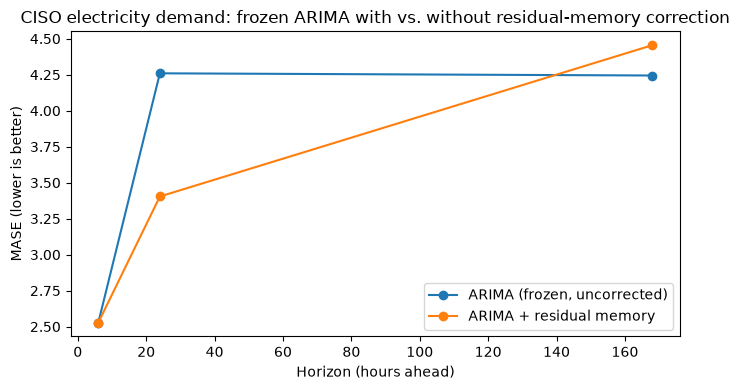

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for model, group in summary.groupby("model"):
    ax.plot(group["horizon"], group["mase"], marker="o", label=model)
ax.set_xlabel("Horizon (hours ahead)")
ax.set_ylabel("MASE (lower is better)")
ax.set_title("CISO electricity demand: frozen ARIMA with vs. without residual-memory correction")
ax.legend()
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/demo2_ciso_mase_by_horizon.png", dpi=150)
plt.show()


In [10]:
summary.to_csv(f"{RESULTS_DIR}/metrics/demo2_ciso_summary.csv", index=False)
all_test_results.to_csv(f"{RESULTS_DIR}/metrics/demo2_ciso_test_forecasts.csv", index=False)


## One example, made concrete

Pick a single test-period forecast origin and look at the base forecast, the corrected
forecast, and what actually happened — plus the historical moments the correction was
retrieved from.

In [11]:
example_origin_date = sorted(o for o in test_origins)
example_origin = example_origin_date[len(example_origin_date) // 2]
example_date = origin_to_date(example_origin)

diagnostics = example_diagnostics[example_date]
neighbor_dates = [origin_to_date(anchor) for anchor in diagnostics["neighbor_anchors"]]
print(f"Forecast origin: {example_date}")
print("Retrieved neighbor windows ended at:")
for date, dist, weight in zip(neighbor_dates, diagnostics["neighbor_distances"], diagnostics["weights"]):
    print(f"  {date}   distance={dist:.3f}   weight={weight:.3f}")


Forecast origin: 2026-08-01 08:00:00+00:00
Retrieved neighbor windows ended at:
  2026-06-13 08:00:00+00:00   distance=0.965   weight=0.232
  2026-07-25 08:00:00+00:00   distance=1.082   weight=0.207
  2026-03-21 08:00:00+00:00   distance=1.160   weight=0.193
  2026-03-20 08:00:00+00:00   distance=1.197   weight=0.187
  2026-07-16 08:00:00+00:00   distance=1.237   weight=0.181


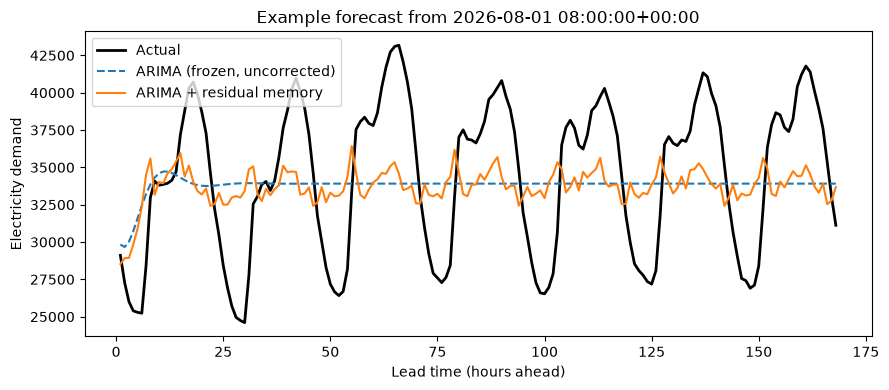

In [12]:
base_path = np.asarray(extended.predict(
    start=example_origin, end=example_origin + MAX_HORIZON - 1, dynamic=True,
))
full_correction, _ = retrieve_residual_correction(
    values, residual_bank, origin=example_origin, lookback=MEMORY_LOOKBACK,
    horizon=MAX_HORIZON, k=N_NEIGHBORS,
)
# The fitted scale is per-horizon (short/medium/long); average them for one illustrative
# path across every lead time from 1 to MAX_HORIZON.
mean_scale = np.mean(list(correction_scale.values()))
corrected_path = base_path + mean_scale * full_correction
actual_path = values[example_origin: example_origin + MAX_HORIZON]

fig, ax = plt.subplots(figsize=(9, 4))
lead_times = np.arange(1, MAX_HORIZON + 1)
ax.plot(lead_times, actual_path, label="Actual", color="black", linewidth=2)
ax.plot(lead_times, base_path, label="ARIMA (frozen, uncorrected)", linestyle="--")
ax.plot(lead_times, corrected_path, label="ARIMA + residual memory")
ax.set_xlabel("Lead time (hours ahead)")
ax.set_ylabel("Electricity demand")
ax.set_title(f"Example forecast from {example_date}")
ax.legend()
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/demo2_ciso_example_forecast.png", dpi=150)
plt.show()


## Reading the results

- Compare MASE (and directional accuracy) between the frozen, uncorrected ARIMA and the
  residual-memory-corrected version, horizon by horizon. An improvement that only shows
  up at some horizons is itself informative about where "the recent situation" is and
  isn't predictive of near-term errors.
- The validation-selected `correction_scale` printed above is worth a second look: a
  scale near 0 at some horizon means validation data found the retrieved correction
  wasn't worth applying there, even if it looked appealing before checking. A scale that
  lands exactly on the edge of `fit_correction_scale`'s search grid is a sign the grid
  itself is too narrow, not that the edge value is actually optimal — widen it and refit.
- A scale chosen on validation can still fail to generalize to test — check the test-set
  MASE against the uncorrected baseline at each horizon rather than assuming the
  validation-time improvement carried over. If it doesn't, that's not a bug in the
  method; it's the validation/test split doing its job of catching a correction that
  doesn't generalize, which is exactly what keeping the scale validation-only is for.
- The single-example plot shows *why* a correction landed where it did — the retrieved
  neighbor dates are prior moments the current lookback window resembled, in normalized
  shape. If those dates look arbitrary rather than situationally similar (e.g. same
  time-of-day/season), that is itself a reason to be skeptical of the correction, even
  where it happens to improve the headline metric.
- The same mechanism applies just as well to correcting a *pretrained* zero-shot
  forecast (e.g. the Chronos-2 forecasts saved by Demo 1) instead of ARIMA — only the
  base forecast and its one-step residual series change; the retrieval and validation-
  scaling logic in `src/residual_memory.py` doesn't care where the base forecast came
  from.
- Set `SMALL_SCALE = False` and rerun for the full-scale numbers used in the blog post.